# Teil 1: Forschungsfragen, Visualisierungen und Hypothesentests

**Position in der Aufgabe:** Dieses Notebook ergänzt die Hypothesentests unter
Transformation Teil 1 und beantwortet F1–F3. Konzept, Lebenszyklus, Ingestion,
Datenprofil, initiale Bereinigung und SQLite-Speicherung sind im README dokumentiert.
Präsentation und Abschlussprüfung: siehe `docs/abgabe_teil1.md`. Der separate Abgabestand liegt auf `abgabe/teil1`.

Quelle: [Open Data Zürich / Bundesamt für Strassen ASTRA](https://data.stadt-zuerich.ch/dataset/sid_dav_strassenverkehrsunfallorte).
Datenbank nur lesend öffnen; weder Daten erneut herunterladen noch bereinigen.
Voraussetzung: `pip install -e ".[dev]"`, danach `python -m de_projekt.pipeline`.

**Vorab festgelegte Regeln:** Alpha 0,05; H1: Wochenende/Werktag × 24 Stunden.
H2: drei getrennte Beteiligungsvergleiche × drei Personenschweregrade mit
Holm-Korrektur innerhalb dieser Testfamilie. H1 ist eine separate Forschungsfrage.
Cramérs V ergänzt p-Werte. Bei erwarteten Zellen unter 5 wird ein reproduzierbarer
Monte-Carlo-Test verwendet, ohne nachträgliches Zusammenlegen für Signifikanz.

Methodenquelle: [SciPy chi2_contingency](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html).
Holm: Holm (1979), Scandinavian Journal of Statistics 6(2), 65–70.
Die p-Werte sind modellbasierte Hinweise auf Zusammenhänge, keine Kausalitätsnachweise.
Der Bestand umfasst registrierte Unfälle; er ist keine Zufallsstichprobe aller
Fahrten. Zeitliche Abhängigkeit und Veränderungen über Jahre begrenzen Inferenz.

**Präzisierte F2:** Besteht bei registrierten Personenschadenunfällen ein Zusammenhang zwischen Fussgänger-, Velo- bzw. Motorradbeteiligung und Unfallschwere? Diese Formulierung gilt für das gesamte Notebook.

In [1]:
import hashlib
import json
import platform
import sqlite3
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import pandas as pd
import scipy
import seaborn as sns
from IPython.display import display

from de_projekt import config, ingestion
from de_projekt.analysis import holm_adjust, independence_test

ALPHA = 0.05
db_path = config.PROCESSED_DIR / config.DATABASE_FILENAME
quality_path = config.PROCESSED_DIR / config.QUALITY_FILENAME
clean_path = config.PROCESSED_DIR / config.CLEAN_FILENAME
quality = json.loads(quality_path.read_text(encoding="utf-8"))
raw_path = ingestion.validate_snapshot(config.RAW_DIR)
source = json.loads((raw_path.parent / "source_metadata.json").read_text(encoding="utf-8-sig"))
connection = sqlite3.connect(db_path.resolve().as_uri() + "?mode=ro", uri=True)
try:
    provenance = dict(connection.execute("SELECT key, value FROM pipeline_metadata"))
    assert connection.execute("PRAGMA integrity_check").fetchone() == ("ok",)
    assert provenance["source_sha256"] == quality["source_sha256"] == source["sha256"]
    assert (
        provenance["clean_sha256"]
        == quality["output_sha256"]
        == hashlib.sha256(clean_path.read_bytes()).hexdigest().upper()
    )
    assert (
        provenance["quality_report_sha256"]
        == hashlib.sha256(quality_path.read_bytes()).hexdigest().upper()
    )
    # SQL wählt nur für F1–F3 benötigte Felder aus.
    data = pd.read_sql_query(
        """
        SELECT AccidentUID, AccidentYear, AccidentWeekDay, AccidentHour,
               AccidentSeverityCategory, AccidentInvolvingPedestrian,
               AccidentInvolvingBicycle, AccidentInvolvingMotorcycle,
               is_weekend, time_period, vulnerable_road_user
        FROM accidents ORDER BY AccidentUID
    """,
        connection,
    )
    sql_annual = pd.read_sql_query(
        """
        SELECT AccidentYear AS year, COUNT(*) AS total,
               SUM(CASE WHEN AccidentSeverityCategory = 'as4' THEN 1 ELSE 0 END) AS property_damage,
               SUM(CASE WHEN AccidentSeverityCategory IN ('as1','as2','as3') THEN 1 ELSE 0 END) AS person_injury
        FROM accidents GROUP BY AccidentYear ORDER BY AccidentYear
    """,
        connection,
    )
finally:
    connection.close()
assert len(data) == int(provenance["rows"]) == quality["rows_after"]
assert data["AccidentUID"].is_unique
figures = config.PROJECT_ROOT / "presentations" / "figures"
figures.mkdir(parents=True, exist_ok=True)
summary = {
    "generated_at": datetime.now(UTC).isoformat(),
    "alpha": ALPHA,
    "source_sha256": provenance["source_sha256"],
    "clean_sha256": provenance["clean_sha256"],
    "database_sha256": hashlib.sha256(db_path.read_bytes()).hexdigest().upper(),
    "versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
    },
    "rows": len(data),
}


def p_text(value):
    return "numerisch 0 (Unterlauf; nicht exakt 0)" if value == 0 else f"{value:.4g}"


display(sql_annual)

,year,total,property_damage,person_injury
0,2011,3420,2348,1072
1,2012,3251,2171,1080
2,2013,3375,2335,1040
3,2014,3293,2229,1064
4,2015,4529,3337,1192
5,2016,5556,4294,1262
6,2017,5548,4310,1238
7,2018,5677,4398,1279
8,2019,5528,4233,1295
9,2020,5039,3803,1236


## F1: Tageszeit und Wochentag

Die Heatmap zeigt registrierte Fallzahlen. Die Stundenkurven sind innerhalb der
Werktag-/Wochenendgruppe auf 100 Prozent normiert: fünf Werktage werden dadurch
nicht einfach mit zwei Wochenendtagen verglichen. Wir berichten keine Unfallrate
pro Verkehrsleistung. Fehlende Zeitangaben werden nur aus dieser Auswertung ausgeschlossen.

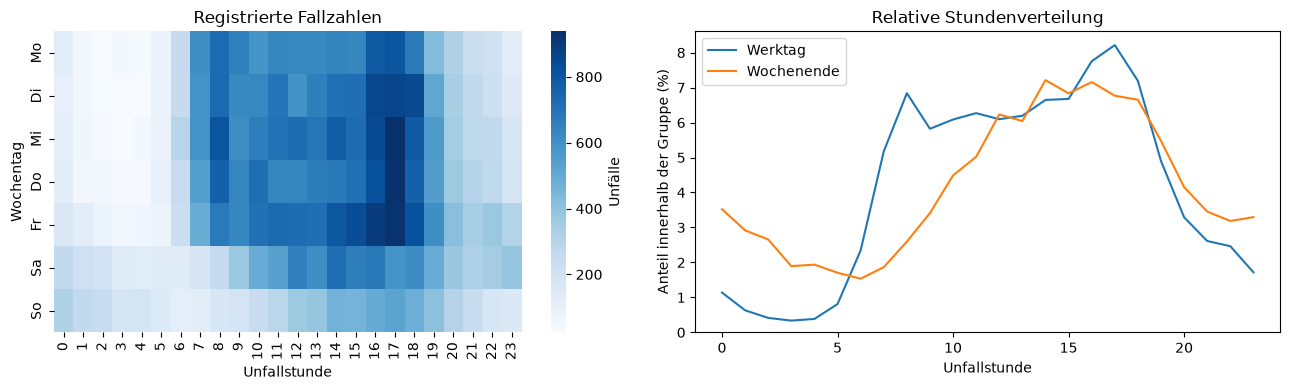

,n,chi2,df,p_value,cramers_v,expected_min,method,excluded_rows
0,70767,3877.063013,23,0.0,0.234065,114.608391,Pearson chi-square (asymptotic),0


H1: H0 verwerfen ; p = numerisch 0 (Unterlauf; nicht exakt 0)


In [2]:
f1 = data.dropna(subset=["AccidentHour", "AccidentWeekDay", "is_weekend"])
hour_table = pd.crosstab(f1["is_weekend"], f1["AccidentHour"]).reindex(
    index=[0, 1], columns=range(24), fill_value=0
)
hourly_share = hour_table.div(hour_table.sum(axis=1), axis=0) * 100
weekdays = [f"aw{i}" for i in range(401, 408)]
weekday_labels = ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"]
heat = pd.crosstab(f1["AccidentWeekDay"], f1["AccidentHour"]).reindex(
    index=weekdays, columns=range(24), fill_value=0
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(
    heat, yticklabels=weekday_labels, cmap="Blues", ax=axes[0], cbar_kws={"label": "Unfälle"}
)
axes[0].set(xlabel="Unfallstunde", ylabel="Wochentag", title="Registrierte Fallzahlen")
for group, label in [(0, "Werktag"), (1, "Wochenende")]:
    axes[1].plot(hourly_share.columns, hourly_share.loc[group], label=label)
axes[1].set(
    xlabel="Unfallstunde",
    ylabel="Anteil innerhalb der Gruppe (%)",
    title="Relative Stundenverteilung",
    ylim=(0, None),
)
axes[1].legend()
fig.tight_layout()
fig.savefig(figures / "f1_zeitmuster.png", dpi=150)
plt.show()

h1 = independence_test(hour_table)
h1.update(
    {
        "hypothesis": "H1",
        "excluded_rows": len(data) - len(f1),
        "reject_h0": h1["p_value"] < ALPHA,
        "counts": hour_table.reset_index().to_dict("records"),
    }
)
summary["h1"] = h1
summary["f1"] = {
    "weekday_counts": heat.sum(axis=1).to_dict(),
    "weekday_peak_hour": int(hourly_share.loc[0].idxmax()),
    "weekend_peak_hour": int(hourly_share.loc[1].idxmax()),
    "night_share_weekday": float(hourly_share.loc[0, 0:5].sum()),
    "night_share_weekend": float(hourly_share.loc[1, 0:5].sum()),
}
display(
    pd.DataFrame(
        [
            {
                key: h1[key]
                for key in [
                    "n",
                    "chi2",
                    "df",
                    "p_value",
                    "cramers_v",
                    "expected_min",
                    "method",
                    "excluded_rows",
                ]
            }
        ]
    )
)
print(
    "H1:",
    "H0 verwerfen" if h1["reject_h0"] else "H0 nicht verwerfen",
    "; p =",
    p_text(h1["p_value"]),
)

### Zeitliche Zusammensetzung als Einschränkung

Zusätzlich betrachten wir den Nachtanteil pro Jahr. Diese deskriptive Kontrolle
hilft, einen über alle Jahre gepoolten Befund einzuordnen. Sie ist kein eigener
Hypothesentest und beseitigt nicht sämtliche zeitlichen Abhängigkeiten.

In [3]:
temporal = (
    f1.assign(is_night=f1["AccidentHour"].between(0, 5))
    .groupby(["AccidentYear", "is_weekend"])
    .agg(n=("AccidentUID", "size"), night_share=("is_night", "mean"))
    .reset_index()
)
temporal["night_share"] *= 100
display(temporal.pivot(index="AccidentYear", columns="is_weekend", values="night_share"))
summary["night_share_by_year"] = temporal.to_dict("records")

is_weekend,0,1
AccidentYear,,
2011,4.486423,20.591581
2012,4.985813,19.387755
2013,4.769351,19.216646
2014,4.335608,20.199501
2015,3.444284,15.549348
2016,3.073013,12.866450
2017,3.283302,12.850467
2018,3.590093,12.225705
2019,3.877409,14.496314


## F2/H2: Verkehrsbeteiligung und Unfallschwere

Primäre Analyse nur für **Personenschadenunfälle** (`as1`, `as2`, `as3`), weil
die Katalogdefinition der Beteiligungsmerkmale unklar zur Sachschadenkategorie
passt. Diese Unklarheit bleibt offen; Sachschadenzeilen werden nicht gelöscht.
Eine positive Beteiligung bedeutet nicht, dass gerade diese Person verletzt wurde.

Je Test vergleichen wir beteiligt/nicht beteiligt × drei Schweregrade. Überlappende
Beteiligungen sind erlaubt: Jeder Unfall zählt je Test genau einmal. Die drei
p-Werte werden gemeinsam nach Holm korrigiert. Die Grafik fasst schwere und
tödliche Unfälle für die Darstellung zusammen, der Test nutzt alle drei Kategorien.

Fussgänger


AccidentSeverityCategory,as3,as2,as1
AccidentInvolvingPedestrian,,,
0,12721,2203,46
1,2446,694,54


AccidentSeverityCategory,as3,as2,as1
AccidentInvolvingPedestrian,,,
0,84.98,14.72,0.31
1,76.58,21.73,1.69


Velo


AccidentSeverityCategory,as3,as2,as1
AccidentInvolvingBicycle,,,
0,9342,1603,78
1,5825,1294,22


...

Motorrad


AccidentSeverityCategory,as3,as2,as1
AccidentInvolvingMotorcycle,,,
0,12883,2360,89
1,2284,537,11


AccidentSeverityCategory,as3,as2,as1
AccidentInvolvingMotorcycle,,,
0,84.03,15.39,0.58
1,80.65,18.96,0.39


,label,n,chi2,df,p_value,p_holm,cramers_v,expected_min,method
0,Fussgänger,18164,194.879486,2,4.813458e-43,1.444038e-42,0.103580,17.584233,Pearson chi-square (asymptotic)
1,Velo,18164,52.601931,2,3.781255e-12,7.562509e-12,0.053814,39.314028,Pearson chi-square (asymptotic)
2,Motorrad,18164,23.960568,2,6.266555e-06,6.266555e-06,0.036320,15.591279,Pearson chi-square (asymptotic)


,participation,involved,n,severe_or_fatal,severe_share_pct
0,Fussgänger,0,14970,2249,15.023380
1,Fussgänger,1,3194,748,23.418910
2,Velo,0,11023,1681,15.249932
3,Velo,1,7141,1316,18.428791
4,Motorrad,0,15332,2449,15.973128
5,Motorrad,1,2832,548,19.350282


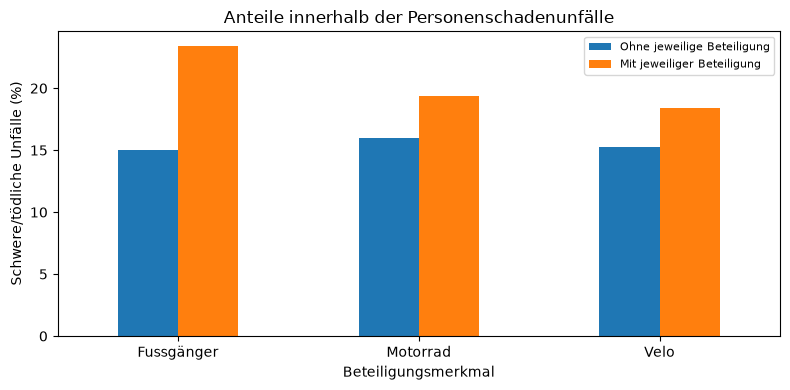

In [4]:
injury = data.loc[data["AccidentSeverityCategory"].isin(["as1", "as2", "as3"])].copy()
features = {
    "AccidentInvolvingPedestrian": "Fussgänger",
    "AccidentInvolvingBicycle": "Velo",
    "AccidentInvolvingMotorcycle": "Motorrad",
}
tests, proportions = [], []
for column, label in features.items():
    subset = injury.dropna(subset=[column])
    table = pd.crosstab(subset[column], subset["AccidentSeverityCategory"]).reindex(
        index=[0, 1], columns=["as3", "as2", "as1"], fill_value=0
    )
    result = independence_test(table)
    result.update(
        {
            "hypothesis": "H2",
            "feature": column,
            "label": label,
            "excluded_missing": len(injury) - len(subset),
            "excluded_property_damage": len(data) - len(injury),
            "counts": table.reset_index().to_dict("records"),
        }
    )
    tests.append(result)
    for involved in [0, 1]:
        n = int(table.loc[involved].sum())
        severe = int(table.loc[involved, ["as2", "as1"]].sum())
        proportions.append(
            {
                "participation": label,
                "involved": involved,
                "n": n,
                "severe_or_fatal": severe,
                "severe_share_pct": 100 * severe / n,
            }
        )
    print(label)
    display(table)
    display(table.div(table.sum(axis=1), axis=0).mul(100).round(2))
corrected = holm_adjust([test["p_value"] for test in tests])
for test, p_adjusted in zip(tests, corrected, strict=True):
    test["p_holm"] = float(p_adjusted)
    test["reject_h0_holm"] = bool(p_adjusted < ALPHA)
summary["h2"] = tests
shares = pd.DataFrame(proportions)
summary["f2_severe_shares"] = proportions
display(
    pd.DataFrame(tests)[
        ["label", "n", "chi2", "df", "p_value", "p_holm", "cramers_v", "expected_min", "method"]
    ]
)
display(shares)
fig, ax = plt.subplots(figsize=(8, 4))
plot = shares.pivot(index="participation", columns="involved", values="severe_share_pct")
plot.columns = ["Ohne jeweilige Beteiligung", "Mit jeweiliger Beteiligung"]
plot.plot.bar(ax=ax, rot=0)
ax.set(
    ylabel="Schwere/tödliche Unfälle (%)",
    xlabel="Beteiligungsmerkmal",
    title="Anteile innerhalb der Personenschadenunfälle",
    ylim=(0, None),
)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures / "f2_beteiligung_schwere.png", dpi=150)
plt.show()

### Deskriptive Kontrolle nach Jahr

Pro Beteiligungsmerkmal und Jahr zeigen wir Fallzahlen und schwere/tödliche
Anteile. Kleine Gruppen können stark schwanken. Diese Tabelle ist eine
Einordnung des gepoolten Befunds und kein adjustierter Kausalitätsnachweis.

In [5]:
yearly_injury = []
for column, label in features.items():
    subset = injury.dropna(subset=[column]).copy()
    subset["severe"] = subset["AccidentSeverityCategory"].isin(["as1", "as2"])
    by_year = (
        subset.groupby(["AccidentYear", column])
        .agg(n=("AccidentUID", "size"), severe_share=("severe", "mean"))
        .reset_index()
    )
    by_year["participation"] = label
    by_year = by_year.rename(columns={column: "involved", "AccidentYear": "year"})
    by_year["severe_share"] *= 100
    yearly_injury.extend(by_year.to_dict("records"))
summary["injury_shares_by_year"] = yearly_injury
display(
    pd.DataFrame(yearly_injury).pivot(
        index=["participation", "year"], columns="involved", values="severe_share"
    )
)

involved                    0          1
participation year                      
Fussgänger    2011  17.061611  28.070175
              2012  18.475751  32.242991
              2013  20.537897  31.981982
              2014  17.016317  25.242718
              2015  13.839750  22.943723
              2016  15.880654  23.766816
              2017  18.062563  26.315789
              2018  14.839319  28.959276
              2019  13.606710  18.918919
              2020  14.540338  17.058824
              2021  13.009709  22.435897
              2022  10.370995  18.181818
              2023  13.396226  16.216216
              2024  13.132296  19.587629
              2025  14.835165  16.972477
Motorrad      2011  17.931034  25.742574
              2012  20.288248  25.842697
              2013  23.137698  22.077922
              2014  17.431193  23.958333
              2015  15.015015  18.652850
              2016  16.511194  21.578947
              2017  19.573643  20.388350
              2018  17.032967  18.716578
              2019  13.818182  18.461538
              2020  14.839319  15.168539
              2021  14.157527  14.754098
              2022  12.016461   8.900524
              2023  12.964642  19.553073
              2024  13.241107  18.571429
              2025  14.695341  18.041237
Velo          2011  19.444444  19.285714
              2012  18.146214  28.662420
              2013  19.315068  31.612903
              2014  15.549215  24.517906
              2015  14.000000  18.325792
              2016  14.936709  21.186441
              2017  16.906946  24.210526
              2018  16.366158  18.458781
              2019  13.755158  15.492958
              2020  12.439418  17.341977
              2021  12.445095  16.699801
              2022  11.989460  11.128284
              2023  11.859838  16.666667
              2024  15.450644  12.428298
              2025  15.236876  15.122873

## F3: Entwicklung von Anzahl und Zusammensetzung

SQL zählt alle Unfälle sowie Personen-/Sachschäden pro Jahr. Pandas ergänzt
relative Schweregrad- und Beteiligungsanteile. Beteiligungsanteile beziehen sich
für den semantisch vorsichtigen Vergleich auf Personenschadenunfälle; ihre Summe
darf wegen Mehrfachbeteiligung über 100 Prozent liegen.

Der Erfassungswechsel im Juli 2015 verbietet einen unkommentierten Vorher-Nachher-
Vergleich der Gesamtzahlen. Jahreszahlen sind keine um Verkehrsleistung bereinigten Risiken.

,year,total,property_damage,person_injury,person_injury_share_pct
0,2011,3420,2348,1072,31.345029
1,2012,3251,2171,1080,33.220548
2,2013,3375,2335,1040,30.814815
3,2014,3293,2229,1064,32.310963
4,2015,4529,3337,1192,26.319276
5,2016,5556,4294,1262,22.714183
6,2017,5548,4310,1238,22.314348
7,2018,5677,4398,1279,22.529505
8,2019,5528,4233,1295,23.426194
9,2020,5039,3803,1236,24.528676


,Fussgänger,Velo,Motorrad
AccidentYear,,,
2011,21.27,26.12,18.84
2012,19.81,29.07,16.48
2013,21.35,29.81,14.81
2014,19.36,34.12,18.05
2015,19.38,37.08,16.19
2016,17.67,37.40,15.06
2017,19.95,38.37,16.64
2018,17.28,43.63,14.62
2019,17.14,43.86,15.06


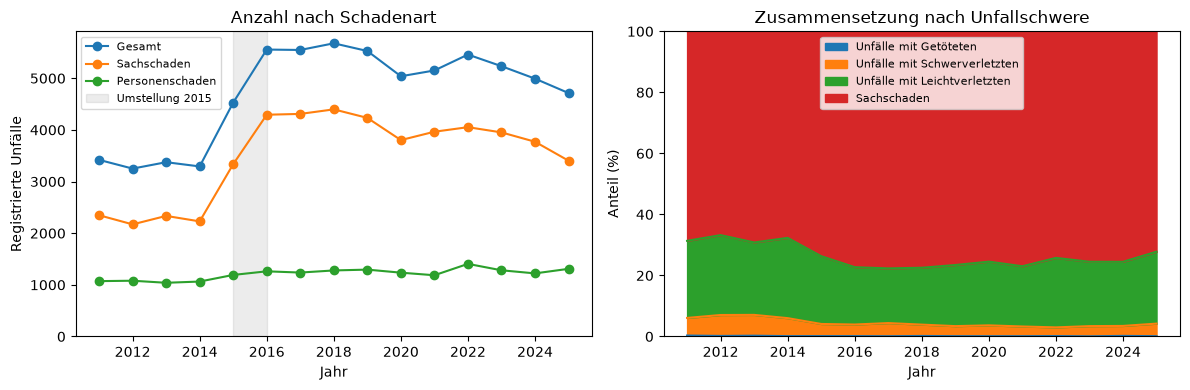

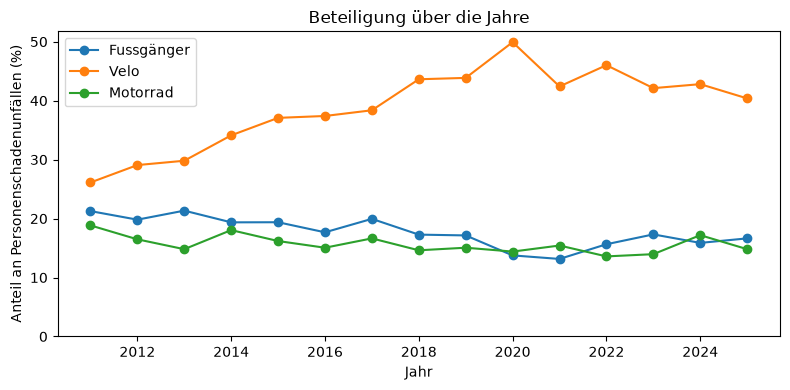

In [6]:
severity = pd.crosstab(data["AccidentYear"], data["AccidentSeverityCategory"]).reindex(
    columns=["as1", "as2", "as3", "as4"], fill_value=0
)
severity_shares = severity.div(severity.sum(axis=1), axis=0) * 100
injury_participation = injury.groupby("AccidentYear")[list(features)].mean() * 100
annual = sql_annual.copy()
annual["person_injury_share_pct"] = annual["person_injury"] / annual["total"] * 100
summary["annual_counts"] = annual.to_dict("records")
summary["severity_shares_by_year"] = (
    severity_shares.rename_axis("year").reset_index().to_dict("records")
)
summary["injury_participation_shares_by_year"] = (
    injury_participation.rename_axis("year").reset_index().to_dict("records")
)
display(annual)
display(injury_participation.rename(columns=features).round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, label in [
    ("total", "Gesamt"),
    ("property_damage", "Sachschaden"),
    ("person_injury", "Personenschaden"),
]:
    axes[0].plot(annual["year"], annual[column], marker="o", label=label)
axes[0].axvspan(2015, 2016, color="grey", alpha=0.15, label="Umstellung 2015")
axes[0].set(
    xlabel="Jahr", ylabel="Registrierte Unfälle", title="Anzahl nach Schadenart", ylim=(0, None)
)
axes[0].legend(fontsize=8)
severity_shares.rename(
    columns={
        "as1": "Unfälle mit Getöteten",
        "as2": "Unfälle mit Schwerverletzten",
        "as3": "Unfälle mit Leichtverletzten",
        "as4": "Sachschaden",
    }
).plot.area(ax=axes[1], stacked=True)
axes[1].set(
    xlabel="Jahr", ylabel="Anteil (%)", title="Zusammensetzung nach Unfallschwere", ylim=(0, 100)
)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures / "f3_jahresvergleich.png", dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
injury_participation.rename(columns=features).plot(ax=ax, marker="o")
ax.set(
    xlabel="Jahr",
    ylabel="Anteil an Personenschadenunfällen (%)",
    title="Beteiligung über die Jahre",
    ylim=(0, None),
)
fig.tight_layout()
fig.savefig(figures / "f3_beteiligungsanteile.png", dpi=150)
plt.show()

## Forschungsfragen beantworten und Ergebnisse exportieren

Die folgenden Antworten werden aus den berechneten Tabellen abgeleitet.
Sie dienen als Arbeitsgrundlage der Präsentation und müssen vom Team erklärt
und hinsichtlich ihrer Einschränkungen geprüft werden. Ein kleiner p-Wert
ersetzt weder Effektgrösse noch praktische Relevanz.

In [7]:
first, last = annual.iloc[0], annual.iloc[-1]
answers = [
    "# Teil 1 – Ergebnisse und Präsentationsgrundlage",
    "",
    "Quelle: Open Data Zürich; Datenlieferant: Bundesamt für Strassen ASTRA.",
    f"Datenstand: {len(data):,} registrierte Unfälle, 2011–2025; Raw-SHA256 `{summary['source_sha256']}`.",
    "",
    "## F1 – Tageszeit und Wochentag",
    f"Die Stundenverteilungen unterscheiden sich: H1 χ²({h1['df']}) = {h1['chi2']:.2f}, p = {p_text(h1['p_value'])}, Cramérs V = {h1['cramers_v']:.3f}.",
    f"H0 wird {'verworfen' if h1['reject_h0'] else 'nicht verworfen'}. Häufigste Stunde: Werktage {summary['f1']['weekday_peak_hour']:02d} Uhr, Wochenende {summary['f1']['weekend_peak_hour']:02d} Uhr.",
    f"Nachtanteil (00–05 Uhr): Werktage {summary['f1']['night_share_weekday']:.2f} %, Wochenende {summary['f1']['night_share_weekend']:.2f} %.",
    "Die Anteile beschreiben registrierte Unfälle innerhalb jeder Gruppe, kein individuelles Unfallrisiko.",
    "",
    "## F2 – Beteiligung und Schwere bei Personenschadenunfällen",
    f"Primäre Analyse: {len(injury):,} Personenschadenunfälle; Sachschäden wegen der Definitionsdiskrepanz separat gehalten.",
]
for test in tests:
    rows = shares.loc[shares["participation"].eq(test["label"])].set_index("involved")
    answers.append(
        f"- {test['label']}: p(Holm) = {p_text(test['p_holm'])}, V = {test['cramers_v']:.3f}; H0 {'verworfen' if test['reject_h0_holm'] else 'nicht verworfen'}. Anteil schwer/tödlich: mit Beteiligung {rows.loc[1, 'severe_share_pct']:.2f} %, ohne {rows.loc[0, 'severe_share_pct']:.2f} %."
    )
answers.extend(
    [
        "Die Anteile beziehen sich auf die Schwere des gesamten Unfalls; sie identifizieren nicht die verletzte Person und belegen keine Ursache.",
        "",
        "## F3 – Veränderung über die Jahre",
        f"Gesamtzahl: {int(first['total']):,} ({int(first['year'])}) → {int(last['total']):,} ({int(last['year'])}); Personenschäden: {int(first['person_injury']):,} → {int(last['person_injury']):,}.",
        "Der Vergleich der Gesamtzahlen wird durch die Sachschaden-Umstellung im Juli 2015 beeinflusst. Deshalb werden Personen-/Sachschäden sowie Anteile getrennt gezeigt.",
    ]
)
for column, label in features.items():
    answers.append(
        f"- {label}-Anteil an Personenschadenunfällen: {injury_participation.loc[2011, column]:.2f} % (2011) → {injury_participation.loc[2025, column]:.2f} % (2025)."
    )
answers.extend(
    [
        "",
        "## Grenzen und offene Abgabeaufgaben",
        "- Keine Verkehrsleistungsdaten: Fallzahlen und Anteile sind keine Risiken pro Fahrt oder Kilometer.",
        "- Modellbasierte p-Werte setzen unabhängige Beobachtungen voraus; Jahreszusammensetzung und zeitliche Abhängigkeit bleiben mögliche Einflüsse.",
        "- Beteiligungsdefinition bei Sachschäden weiterhin unklar; keine automatische Korrektur behauptet.",
        "- Mehrfachbeteiligung: Beteiligungsanteile sind nicht gegenseitig ausschliessend.",
        "- Die Präsentation muss Konzept und Begründungen ebenso wie diese Ergebnisse enthalten.",
        "- Teamreview, Präsentation und eingefrorener Abgabe-Branch stehen noch aus.",
    ]
)
# Deskriptive Review-Kontrollen aus aktuellen Tabellen, nicht fest codieren.
night_years = temporal.pivot(index="AccidentYear", columns="is_weekend", values="night_share")
review_yearly = pd.DataFrame(yearly_injury)
max_year = int(annual.loc[annual["total"].idxmax(), "year"])
max_count = int(annual["total"].max())
after_change = annual.loc[annual["year"].ge(2016)].iloc[0]
answers.extend(
    [
        "",
        "## Präzisierungen aus dem fachlichen Review",
        f"Der höhere Nachtanteil am Wochenende zeigt sich in {int((night_years[1] > night_years[0]).sum())}/{len(night_years)} Jahren. Die folgenden Kontrollen sind deskriptiv, keine adjustierten Tests.",
    ]
)
for label in features.values():
    rates = review_yearly.loc[review_yearly["participation"].eq(label)].pivot(
        index="year", columns="involved", values="severe_share"
    )
    answers.append(
        f"- {label}: höherer Anteil schwerer/tödlicher Unfälle mit Beteiligung in {int((rates[1] > rates[0]).sum())}/{len(rates)} Jahren."
    )
answers.extend(
    [
        f"Keine stetige Zunahme: Maximum {max_year} mit {max_count:,} Unfällen; {int(after_change['year'])}–{int(last['year'])} Gesamtzahl {int(after_change['total']):,} → {int(last['total']):,}, Personenschäden {int(after_change['person_injury']):,} → {int(last['person_injury']):,}.",
        "Details und Grenzen des Reviews des ursprünglichen Snapshots: docs/fachliches_review_teil1.md.",
    ]
)
results_path = config.PROJECT_ROOT / "presentations" / "teil1_ergebnisse.md"
results_path.write_text("\n".join(answers) + "\n", encoding="utf-8")
(config.PROCESSED_DIR / "analysis_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
pd.DataFrame(
    [
        {
            key: test[key]
            for key in [
                "label",
                "n",
                "chi2",
                "df",
                "p_value",
                "p_holm",
                "cramers_v",
                "expected_min",
                "method",
            ]
        }
        for test in tests
    ]
).to_csv(config.PROCESSED_DIR / "hypothesis_tests_h2.csv", index=False)
annual.to_csv(config.PROCESSED_DIR / "annual_counts.csv", index=False)
display(results_path.read_text(encoding="utf-8"))
print("Datenbank und Raw-Snapshot wurden nicht verändert.")

'# Teil 1 – Ergebnisse und Präsentationsgrundlage\n\nQuelle: Open Data Zürich; Datenlieferant: Bundesamt für Strassen ASTRA.\nDatenstand: 70,767 registrierte Unfälle, 2011–2025; Raw-SHA256 `DF426E859FECD37CD7365F273662459688B1862482957960402696E8722D766F`.\n\n## F1 – Tageszeit und Wochentag\nDie Stundenverteilungen unterscheiden sich: H1 χ²(23) = 3877.06, p = numerisch 0 (Unterlauf; nicht exakt 0), Cramérs V = 0.234.\nH0 wird verworfen. Häufigste Stunde: Werktage 17 Uhr, Wochenende 14 Uhr.\nNachtanteil (00–05 Uhr): Werktage 3.71 %, Wochenende 14.63 %.\nDie Anteile beschreiben registrierte Unfälle innerhalb jeder Gruppe, kein individuelles Unfallrisiko.\n\n## F2 – Beteiligung und Schwere bei Personenschadenunfällen\nPrimäre Analyse: 18,164 Personenschadenunfälle; Sachschäden wegen der Definitionsdiskrepanz separat gehalten.\n- Fussgänger: p(Holm) = 1.444e-42, V = 0.104; H0 verworfen. Anteil schwer/tödlich: mit Beteiligung 23.42 %, ohne 15.02 %.\n- Velo: p(Holm) = 7.563e-12, V = 0.054; H

Datenbank und Raw-Snapshot wurden nicht verändert.
